## Section0 Imports and Settings

In [30]:
import pandas as pd
import numpy as np
import altair as alt
from pathlib import Path

## Section1 billionaire, country

In [31]:
df_071 = pd.read_csv("../data/dataset_2026-10-17IMF.csv")
df_071.head()

/var/folders/3w/plrcmbn551b7m7src59wh39w0000gn/T/ipykernel_54902/415551028.py:1: DtypeWarning: Columns (13: LATEST_ACTUAL_ANNUAL_DATA, 15: BASE_YEAR, 21: LABOR_SECTOR_EMPLOYMENT_TYPE, 24: FISCAL_SECTOR_INSTRUMENTS_INCLUDED_IN_GROSS_AND_NET_DEBT) have mixed types. Specify dtype option on import or set low_memory=False.
  df_071 = pd.read_csv("../data/dataset_2026-10-17IMF.csv")


,DATASET,SERIES_CODE,OBS_MEASURE,COUNTRY,INDICATOR,FREQUENCY,SCALE,UNIT,COUNTRY_UPDATE_DATE,PUBLICATION_DATE,...,2022,2023,2024,2025,2026,2027,2028,2029,2030,2031
0,IMF.RES:WEO(9.0.0),SYR.GGX_NGDP.A,OBS_VALUE,Syrian Arab Republic,"Expenditure, General government, Percent of GDP",Annual,Units,Percent,NaN,2026-10-13T02:00:00Z,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,IMF.RES:WEO(9.0.0),SYR.PPPPC.A,OBS_VALUE,Syrian Arab Republic,"Gross domestic product (GDP), Per capita, purc...",Annual,Units,NaN,NaN,2026-10-13T02:00:00Z,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,IMF.RES:WEO(9.0.0),SYR.GGR_NGDP.A,OBS_VALUE,Syrian Arab Republic,"Revenue, General government, Percent of GDP",Annual,Units,Percent,NaN,2026-10-13T02:00:00Z,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,IMF.RES:WEO(9.0.0),SYR.PCPIE.A,OBS_VALUE,Syrian Arab Republic,"All Items, Consumer price index (CPI), End-of-...",Annual,Units,Index,NaN,2026-10-13T02:00:00Z,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,IMF.RES:WEO(9.0.0),SYR.PPPGDP.A,OBS_VALUE,Syrian Arab Republic,"Gross domestic product (GDP), Current prices, ...",Annual,Billions,NaN,NaN,2026-10-13T02:00:00Z,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [32]:
df_072 = pd.read_csv("../data/billionaires.csv")
df_072.head(10)

,name,category,usd_billions,year,as_of,source,source_url
0,Elon Musk,Individual net worth,908.5,2026,10/17/26,Forbes real-time billionaires,https://www.forbes.com/real-time-billionaires/
1,Jeff Bezos,Individual net worth,369.8,2026,10/17/26,Forbes real-time billionaires,https://www.forbes.com/real-time-billionaires/
2,Larry Page,Individual net worth,279.3,2026,10/17/26,Forbes real-time billionaires,https://www.forbes.com/real-time-billionaires/
3,Sergey Brin,Individual net worth,257.1,2026,10/17/26,Forbes real-time billionaires,https://www.forbes.com/real-time-billionaires/
4,Mark Zuckerberg,Individual net worth,243.3,2026,10/17/26,Forbes real-time billionaires,https://www.forbes.com/real-time-billionaires/
5,Michael Dell,Individual net worth,237.0,2026,10/17/26,Forbes real-time billionaires,https://www.forbes.com/real-time-billionaires/
6,Jensen Huang,Individual net worth,185.6,2026,10/17/26,Forbes real-time billionaires,https://www.forbes.com/real-time-billionaires/
7,Larry Ellison,Individual net worth,167.2,2026,10/17/26,Forbes real-time billionaires,https://www.forbes.com/real-time-billionaires/
8,Steve Ballmer,Individual net worth,163.5,2026,10/17/26,Forbes real-time billionaires,https://www.forbes.com/real-time-billionaires/
9,Warren Buffett,Individual net worth,151.1,2026,10/17/26,Forbes real-time billionaires,https://www.forbes.com/real-time-billionaires/


In [33]:
imf = df_071[
    df_071["SERIES_CODE"].str.contains(
        r"\.(GGX_NGDP|NGDPD)\.A$", regex=True, na=False
    )
][["COUNTRY", "SERIES_CODE", "2026"]].copy()

imf["indicator"] = imf["SERIES_CODE"].str.extract(
    r"\.(GGX_NGDP|NGDPD)\.A$"
)

imf["2026"] = pd.to_numeric(imf["2026"], errors="coerce")

# One row per country
imf_wide = imf.pivot(
    index="COUNTRY",
    columns="indicator",
    values="2026"
).reset_index()

# Projected government expenditure, USD billions
imf_wide["budget_usd_billions"] = (
    imf_wide["NGDPD"] *
    imf_wide["GGX_NGDP"] / 100
)

imf_wide.head()

/var/folders/3w/plrcmbn551b7m7src59wh39w0000gn/T/ipykernel_54902/2126243610.py:2: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_071["SERIES_CODE"].str.contains(


indicator,COUNTRY,GGX_NGDP,NGDPD,budget_usd_billions
0,ASEAN-5,19.777,3795.751,750.685675
1,Advanced Economies,41.416,74234.689,30745.038796
2,"Afghanistan, Islamic Republic of",NaN,NaN,NaN
3,Albania,31.741,32.769,10.401208
4,Algeria,35.059,331.894,116.358717


In [34]:
# added

top10_countries = (
    imf_wide
    .dropna(subset=["budget_usd_billions"])
    .sort_values("budget_usd_billions", ascending=False)
    .head(20)
    .copy()
)

top10_countries = top10_countries[
    ["COUNTRY", "budget_usd_billions"]
]

print("Top 10 Countries by Government Expenditure (2026)")
display(top10_countries.round(1))

Top 10 Countries by Government Expenditure (2026)


indicator,COUNTRY,budget_usd_billions
1,Advanced Economies,30745.0
68,G7,23296.4
55,Emerging Market and Developing Economies,17008.2
199,United States,12482.4
64,European Union (EU),11412.7
63,Euro Area (EA),9706.8
56,Emerging and Developing Asia,9047.1
38,"China, People's Republic of",6974.6
142,Other Advanced Economies (Advanced Economies e...,3966.0
57,Emerging and Developing Europe,2949.1


In [35]:

from pathlib import Path

# Sort all countries by projected government expenditure
government_spending_2026 = (
    imf_wide[
        ["COUNTRY", "NGDPD", "GGX_NGDP", "budget_usd_billions"]
    ]
    .dropna(subset=["budget_usd_billions"])
    .sort_values("budget_usd_billions", ascending=False)
    .reset_index(drop=True)
)

# Add ranking and USD trillions
government_spending_2026.insert(
    0, "Rank", range(1, len(government_spending_2026) + 1)
)

government_spending_2026["budget_usd_trillions"] = (
    government_spending_2026["budget_usd_billions"] / 1000
)

# Display every country in the notebook
print(government_spending_2026.to_string(index=False))

# Export CSV
output_path = Path("../data/government_spending_2026.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

government_spending_2026.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print(f"\nExported {len(government_spending_2026)} countries to {output_path}")


 Rank                                                                            COUNTRY     NGDPD  GGX_NGDP  budget_usd_billions  budget_usd_trillions
    1                                                                 Advanced Economies 74234.689    41.416         30745.038796             30.745039
    2                                                                                 G7 55470.253    41.998         23296.396855             23.296397
    3                                           Emerging Market and Developing Economies 53769.087    31.632         17008.237600             17.008238
    4                                                                      United States 32642.373    38.240         12482.443435             12.482443
    5                                                                European Union (EU) 22806.152    50.042         11412.654584             11.412655
    6                                                                     Euro Area (EA)

In [36]:
selected_countries = [
    "United States",
    "China, People's Republic of",
    "Germany",
    "United Kingdom",
    "Japan",
    "Brazil",
    "India",
    "Russian Federation",
    "Australia",
    "Mexico",
    "Saudi Arabia",
    "Indonesia",
    "Colombia",
    "Portugal",
    "South Africa",
    "Egypt, Arab Republic of",
    "Vietnam",
    "Bangladesh"
]

countries = imf_wide[
    imf_wide["COUNTRY"].isin(selected_countries)
].dropna(subset=["budget_usd_billions"]).copy()

countries = countries.rename(columns={
    "COUNTRY": "name",
    "budget_usd_billions": "usd_billions"
})

countries["category"] = "Government expenditure forecast"

chart07_data = pd.concat([
    df_072[["name", "category", "usd_billions"]],
    countries[["name", "category", "usd_billions"]]
], ignore_index=True)

chart07_data = chart07_data.sort_values(
    "usd_billions", ascending=False
)

chart07_data

,name,category,usd_billions
26,United States,Government expenditure forecast,12482.443435
13,"China, People's Republic of",Government expenditure forecast,6974.570651
16,Germany,Government expenditure forecast,2801.578653
25,United Kingdom,Government expenditure forecast,1855.066632
19,Japan,Government expenditure forecast,1625.900078
12,Brazil,Government expenditure forecast,1291.912893
17,India,Government expenditure forecast,1157.037189
22,Russian Federation,Government expenditure forecast,1122.946507
0,Elon Musk,Individual net worth,908.500000
10,Australia,Government expenditure forecast,839.197223


In [37]:
print(countries[["name", "usd_billions"]])
print("Total observations:", len(chart07_data))

indicator                         name  usd_billions
11                           Australia    839.197223
16                          Bangladesh     53.618143
26                              Brazil   1291.912893
38         China, People's Republic of   6974.570651
39                            Colombia    198.922320
53             Egypt, Arab Republic of    123.631627
72                             Germany   2801.578653
85                               India   1157.037189
86                           Indonesia    249.549843
93                               Japan   1625.900078
122                             Mexico    633.654636
151                           Portugal    167.480437
155                 Russian Federation   1122.946507
159                       Saudi Arabia    379.750481
169                       South Africa    162.047870
198                     United Kingdom   1855.066632
199                      United States  12482.443435
204                            Vietnam    115.

In [38]:
def make_bubble_chart(data, max_size, title):
    return (
        alt.Chart(data)
        .mark_circle(opacity=0.65, stroke="white", strokeWidth=1)
        .encode(
            x=alt.X(
                "usd_billions:Q",
                title="Net worth / projected annual expenditure (USD billions)",
                scale=alt.Scale(zero=True)
            ),
            y=alt.Y(
                "name:N",
                sort=alt.SortField(
                    field="usd_billions",
                    order="descending"
                ),
                title=None
            ),
            size=alt.Size(
                "usd_billions:Q",
                scale=alt.Scale(range=[100, max_size]),
                legend=None
            ),
            color=alt.Color(
                "category:N",
                scale=alt.Scale(
                    domain=[
                        "Individual net worth",
                        "Government expenditure forecast",
                        "Top 10 combined wealth"
                    ],
                    range=["#A51A0D", "#A0A1A2", "#E6B422"]
                ),
                legend=alt.Legend(title="Category")
            ),
            tooltip=[
                "name:N",
                "category:N",
                alt.Tooltip(
                    "usd_billions:Q",
                    title="USD billions",
                    format=",.1f"
                )
            ]
        )
        .properties(
            width=750,
            height=550,
            title=title
        )
    )

In [39]:
top10_total = df_072["usd_billions"].sum()

top10_row = pd.DataFrame([{
    "name": "Top 10 Combined",
    "category": "Top 10 combined wealth",
    "usd_billions": top10_total
}])

chart07_data = pd.concat(
    [chart07_data, top10_row],
    ignore_index=True
)

print(f"Top 10 combined: ${top10_total:,.1f} billion")

Top 10 combined: $2,962.4 billion


In [40]:
chart07a = make_bubble_chart(
    chart07_data,
    max_size=10000,
    title="Billionaire Wealth vs. Government Spending Forecasts (2026)"
)

chart07a

alt.Chart(...)

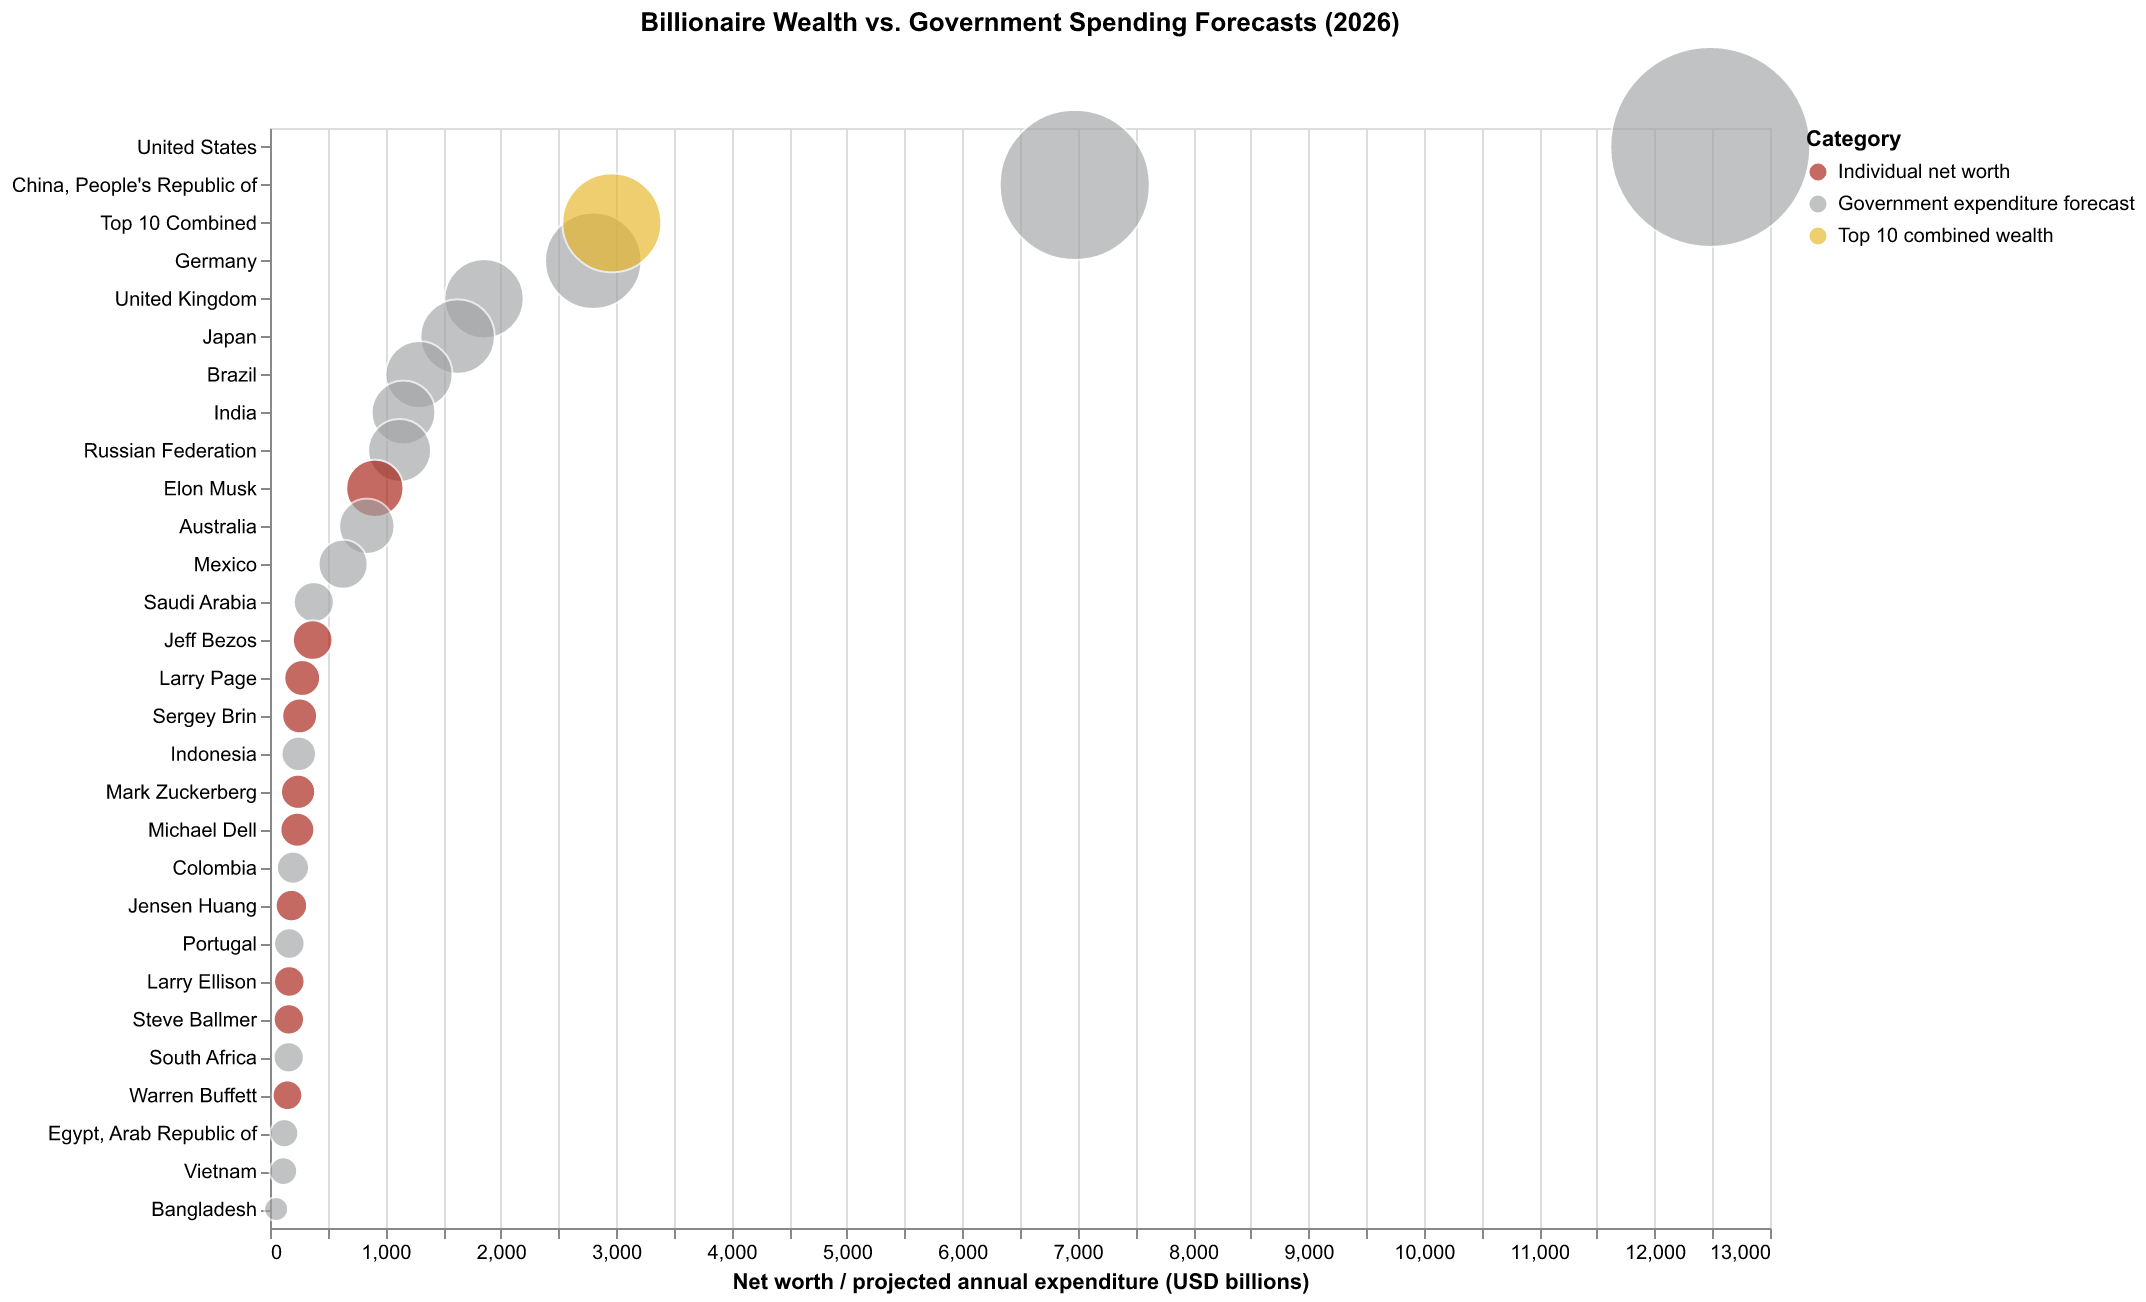

In [91]:
chart07a.save("../img/01.png", scale_factor=2)
chart07a.save("../img/01.svg")
display(Image(filename="../img/01.png"))

## Section2 proportion by wealth group

In [50]:
DATA_PATH2 = Path("../data/dfa-networth-levels.csv")

variables = ["Date", "Category", "Net worth"]

df_wealth = pd.read_csv(DATA_PATH2, usecols=variables)

df_wealth["Year"] = df_wealth["Date"].str[:4].astype(int)

df_wealth["Wealth group"] = df_wealth["Category"].replace({
    "TopPt1": "Top 1%",
    "RemainingTop1": "Top 1%",
    "Next9": "Next 9%",
    "Next40": "Middle 40%",
    "Bottom50": "Bottom 50%"
})

df_wealth["Wealth (trillions)"] = df_wealth["Net worth"] / 1_000_000

df_wealth_selected = df_wealth[
    (df_wealth["Date"] == "1990:Q3") |
    (
        (df_wealth["Year"] % 5 == 0) &
        (df_wealth["Date"].str.endswith("Q3"))
    )
].copy()

wealth_summary = (
    df_wealth_selected
    .groupby(["Date", "Wealth group"], as_index=False)["Wealth (trillions)"]
    .sum()
)

wealth_summary.head()

,Date,Wealth group,Wealth (trillions)
0,1990:Q3,Bottom 50%,0.744277
1,1990:Q3,Middle 40%,7.685969
2,1990:Q3,Next 9%,7.858272
3,1990:Q3,Top 1%,4.721261
4,1995:Q3,Bottom 50%,1.024037


In [51]:
df_wealth["Year"] = df_wealth["Date"].str[:4].astype(int)

# Combine the two top-1% categories
df_wealth["Wealth group"] = df_wealth["Category"].replace({
    "TopPt1": "Top 1%",
    "RemainingTop1": "Top 1%",
    "Next9": "Next 9%",
    "Next40": "Middle 40%",
    "Bottom50": "Bottom 50%"
})

# Federal Reserve figures are in millions of dollars
df_wealth["Wealth (trillions)"] = df_wealth["Net worth"] / 1_000_000

# Keep Q3 for every fifth year, starting in 1990
# 1989 Q3 is the earliest observation, so include it separately
df_wealth_selected = df_wealth[
    (df_wealth["Date"] == "1990:Q3") |
    (
        (df_wealth["Year"] % 5 == 0) &
        (df_wealth["Date"].str.endswith("Q3"))
    )
].copy()

wealth_summary = (
    df_wealth_selected
    .groupby(["Date", "Wealth group"], as_index=False)["Wealth (trillions)"]
    .sum()
)
wealth_summary["stack_order"] = wealth_summary["Wealth group"].map({
    "Top 1%": 0,
    "Next 9%": 1,
    "Middle 40%": 2,
    "Bottom 50%": 3
})

wealth_order = [
    "Bottom 50%",
    "Middle 40%",
    "Next 9%",
    "Top 1%"
]

legend_order = [
    "Top 1%",
    "Next 9%",
    "Middle 40%",
    "Bottom 50%"
]

wealth_summary.head(10)

,Date,Wealth group,Wealth (trillions),stack_order
0,1990:Q3,Bottom 50%,0.744277,3
1,1990:Q3,Middle 40%,7.685969,2
2,1990:Q3,Next 9%,7.858272,1
3,1990:Q3,Top 1%,4.721261,0
4,1995:Q3,Bottom 50%,1.024037,3
5,1995:Q3,Middle 40%,9.787954,2
6,1995:Q3,Next 9%,9.455381,1
7,1995:Q3,Top 1%,7.619192,0
8,2000:Q3,Bottom 50%,1.377520,3
9,2000:Q3,Middle 40%,14.322877,2


In [52]:
wealth_order = [
    "Bottom 50%",
    "Middle 40%",
    "Next 9%",
    "Top 1%"
]

chart06a = alt.Chart(wealth_summary).mark_line(
    point=True,
    strokeWidth=3
).encode(
    x=alt.X(
        "Date:O",
        title="Year",
        sort="ascending",
        axis=alt.Axis(labelAngle=0)
    ),
    y=alt.Y(
        "Wealth (trillions):Q",
        title="Household net worth ($ trillions)",
        scale=alt.Scale(zero=True)
    ),
    color=alt.Color(
        "Wealth group:N",
        scale=alt.Scale(
            domain=wealth_order,
            range=["#0E9613", "#9ADF46", "#EE9944", "#A51A0D"]
        ),
        legend=alt.Legend(
            title="Wealth group",
            values=wealth_order
        )
    ),
    tooltip=[
        "Date:O",
        "Wealth group:N",
        alt.Tooltip(
            "Wealth (trillions):Q",
            format=".2f",
            title="Wealth ($ trillions)"
        )
    ]
).properties(
    width=750,
    height=400,
    title="U.S. Household Wealth by Wealth Group Over Time"
)

chart06a


alt.Chart(...)

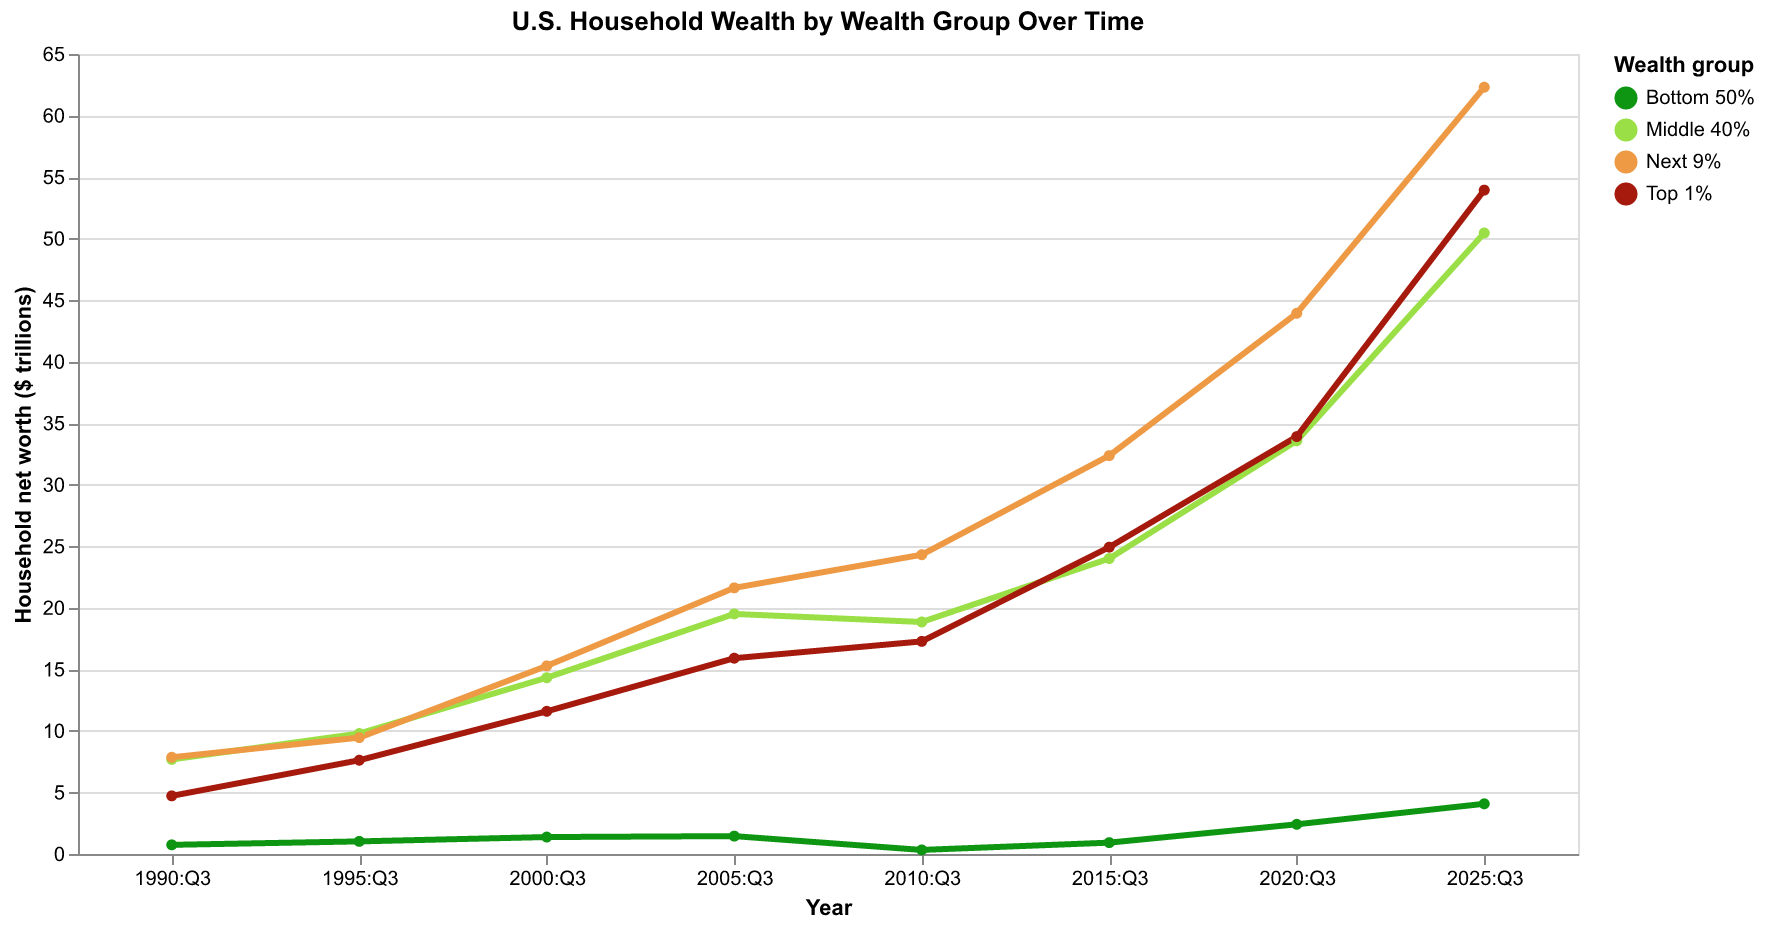

In [90]:
chart06a.save("../img/02a.png", scale_factor=2)
chart06a.save("../img/02a.svg")
display(Image(filename="../img/02a.png"))

In [55]:
DATA_PATH3 = Path("../data/dfa-networth-shares.csv")

variables = [
	"Date",
    "Category",
    "Net worth"
]

df_wealth2 = pd.read_csv(DATA_PATH3, usecols=variables)

In [58]:
df_wealth2["Year"] = df_wealth2["Date"].str[:4].astype(int)

df_wealth2["Wealth group"] = df_wealth2["Category"].replace({
    "TopPt1": "Top 1%",
    "RemainingTop1": "Top 1%",
    "Next9": "Next 9%",
    "Next40": "Middle 40%",
    "Bottom50": "Bottom 50%"
})

df_wealth2_selected = df_wealth2[
    (df_wealth2["Year"] % 5 == 0) &
    (df_wealth2["Date"].str.endswith("Q3"))
].copy()

wealth_shares = (
    df_wealth2_selected
    .groupby(["Date", "Wealth group"], as_index=False)["Net worth"]
    .sum()
)

wealth_shares["stack_order"] = wealth_shares["Wealth group"].map({
    "Top 1%": 0,
    "Next 9%": 1,
    "Middle 40%": 2,
    "Bottom 50%": 3
})

wealth_order = [
    "Bottom 50%",
    "Middle 40%",
    "Next 9%",
    "Top 1%"
]

legend_order = [
    "Top 1%",
    "Next 9%",
    "Middle 40%",
    "Bottom 50%"
]
wealth_shares.head(10)

,Date,Wealth group,Net worth,stack_order
0,1990:Q3,Bottom 50%,3.5,3
1,1990:Q3,Middle 40%,36.6,2
2,1990:Q3,Next 9%,37.4,1
3,1990:Q3,Top 1%,22.4,0
4,1995:Q3,Bottom 50%,3.7,3
5,1995:Q3,Middle 40%,35.1,2
6,1995:Q3,Next 9%,33.9,1
7,1995:Q3,Top 1%,27.3,0
8,2000:Q3,Bottom 50%,3.2,3
9,2000:Q3,Middle 40%,33.6,2


In [59]:
wealth_shares["Share (%)"] = (
    wealth_shares["Net worth"] /
    wealth_shares.groupby("Date")["Net worth"].transform("sum") * 100
)

In [66]:
wealth_order = [
    "Bottom 50%",
    "Middle 40%",
    "Next 9%",
    "Top 1%"
]

chart06b = alt.Chart(wealth_shares).mark_bar().encode(
    x=alt.X(
        "Date:N",
        title="Year",
        sort=alt.SortField("Date", order="ascending"),
        axis=alt.Axis(labelAngle=0)
    ),
    y=alt.Y(
        "Share (%):Q",
        title="Share of total household wealth (%)",
        scale=alt.Scale(domain=[0, 100])
    ),
    color=alt.Color(
        "Wealth group:N",
        scale=alt.Scale(
            domain=wealth_order,
            range=["#0E9613", "#9ADF46", "#EE9944", "#A51A0D"]
        ),
        legend=alt.Legend(
        title="Wealth group",
        values=legend_order
        )
    ),
    order=alt.Order("stack_order:Q", sort="descending"),
    tooltip=[
        "Date:N",
        "Wealth group:N",
        alt.Tooltip("Share (%):Q", format=".1f")
    ]
).properties(
    width=750,
    height=400,
    title="Who Owns America's Wealth? Distribution by Wealth Group"
)

chart06b

alt.Chart(...)

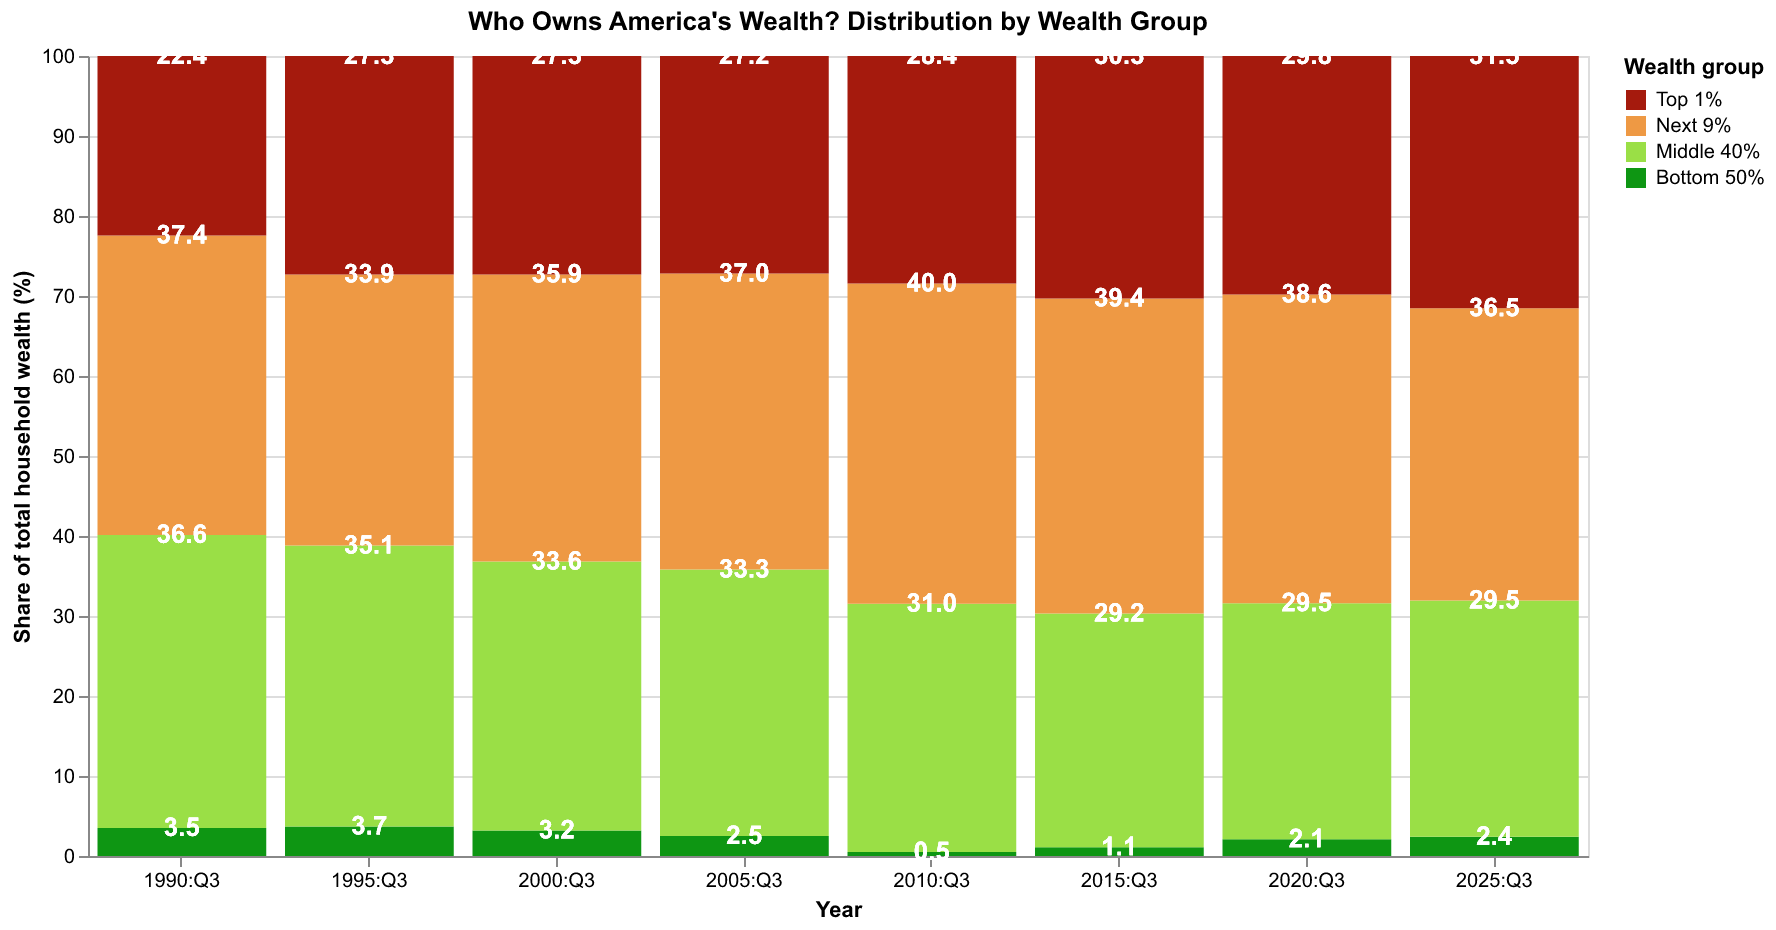

In [89]:
# Percentage labels inside each stacked bar
labels06b = alt.Chart(wealth_shares).mark_text(
    color="white",
    fontSize=13,
    fontWeight="bold"
).encode(
    x=alt.X(
        "Date:N",
        sort=alt.SortField("Date", order="ascending")
    ),
    y=alt.Y(
        "Share (%):Q",
        stack="center"
    ),
    text=alt.Text(
        "Share (%):Q",
        format=".1f"
    ),
    detail="Wealth group:N",
    order=alt.Order(
        "stack_order:Q",
        sort="descending"
    )
)

# Combine bars and labels
chart06b = chart06b + labels06b

from IPython.display import Image, display

chart06b.save("../img/02b.png", scale_factor=2)
chart06b.save("../img/02b.svg")
display(Image(filename="../img/02b.png"))

## Section3 Income source

In [68]:
# 1. Load data
df = pd.read_csv("../data/SCFP2022.csv")

income_sources = {
    "WAGEINC": "Wages",
    "BUSSEFARMINC": "Business income",
    "INTDIVINC": "Interest & dividends",
    "KGINC": "Capital gains"
}

income_order = [
    "Bottom 50%",
    "Next 40%",
    "Next 9%",
    "Top 1%"
]

# 2. Identify the five imputations per family
df["implicate"] = df.groupby("YY1").cumcount() + 1

# 3. Assign income groups using survey-weighted percentiles
def assign_income_group(data):
    data = data.sort_values("INCOME").copy()

    data["percentile"] = (
        data["WGT"].cumsum() - data["WGT"] / 2
    ) / data["WGT"].sum()

    data["Income group"] = pd.cut(
        data["percentile"],
        bins=[0, 0.50, 0.90, 0.99, 1.0],
        labels=income_order,
        include_lowest=True
    )

    return data

df = pd.concat(
    [assign_income_group(d) for _, d in df.groupby("implicate")],
    ignore_index=True
)

# Divide weights by five to account for the five imputations
df["weight"] = df["WGT"] / 5

# 4. Calculate income shares within each group
rows = []

for group, data in df.groupby("Income group", observed=True):

    total_income = (
        data["INCOME"] * data["weight"]
    ).sum()

    for variable, label in income_sources.items():

        source_income = (
            data[variable] * data["weight"]
        ).sum()

        rows.append({
            "Income group": str(group),
            "Income source": label,
            "Share (%)": source_income / total_income * 100
        })

chart_data = pd.DataFrame(rows)

# 5. Display exact percentages
income_table = chart_data.pivot(
    index="Income group",
    columns="Income source",
    values="Share (%)"
).reindex(income_order)

display(income_table.round(1))

# 6. Create grouped bar chart
source_order = list(income_sources.values())

chart05b = alt.Chart(chart_data).mark_bar().encode(
    x=alt.X(
        "Income group:N",
        sort=income_order,
        title="Family income group",
        axis=alt.Axis(labelAngle=0)
    ),
    xOffset=alt.XOffset(
        "Income source:N",
        sort=source_order
    ),
    y=alt.Y(
        "Share (%):Q",
        title="Share of total family income (%)"
    ),
    color=alt.Color(
        "Income source:N",
        scale=alt.Scale(
            domain=source_order,
            range=["#0E9613", "#9ADF46", "#EE9944", "#A51A0D"]
        ),
        legend=alt.Legend(title="Income source")
    ),
    tooltip=[
        "Income group:N",
        "Income source:N",
        alt.Tooltip("Share (%):Q", format=".1f")
    ]
).properties(
    width=750,
    height=400,
    title="Where Does the Money Come From? (2022 SCF)"
)

chart05b


/var/folders/3w/plrcmbn551b7m7src59wh39w0000gn/T/ipykernel_54902/2283041247.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["implicate"] = df.groupby("YY1").cumcount() + 1


Income source,Business income,Capital gains,Interest & dividends,Wages
Income group,,,,
Bottom 50%,6.0,0.7,1.1,52.8
Next 40%,8.0,1.8,1.4,72.8
Next 9%,13.5,9.5,4.9,62.9
Top 1%,25.1,30.5,6.0,35.1


alt.Chart(...)

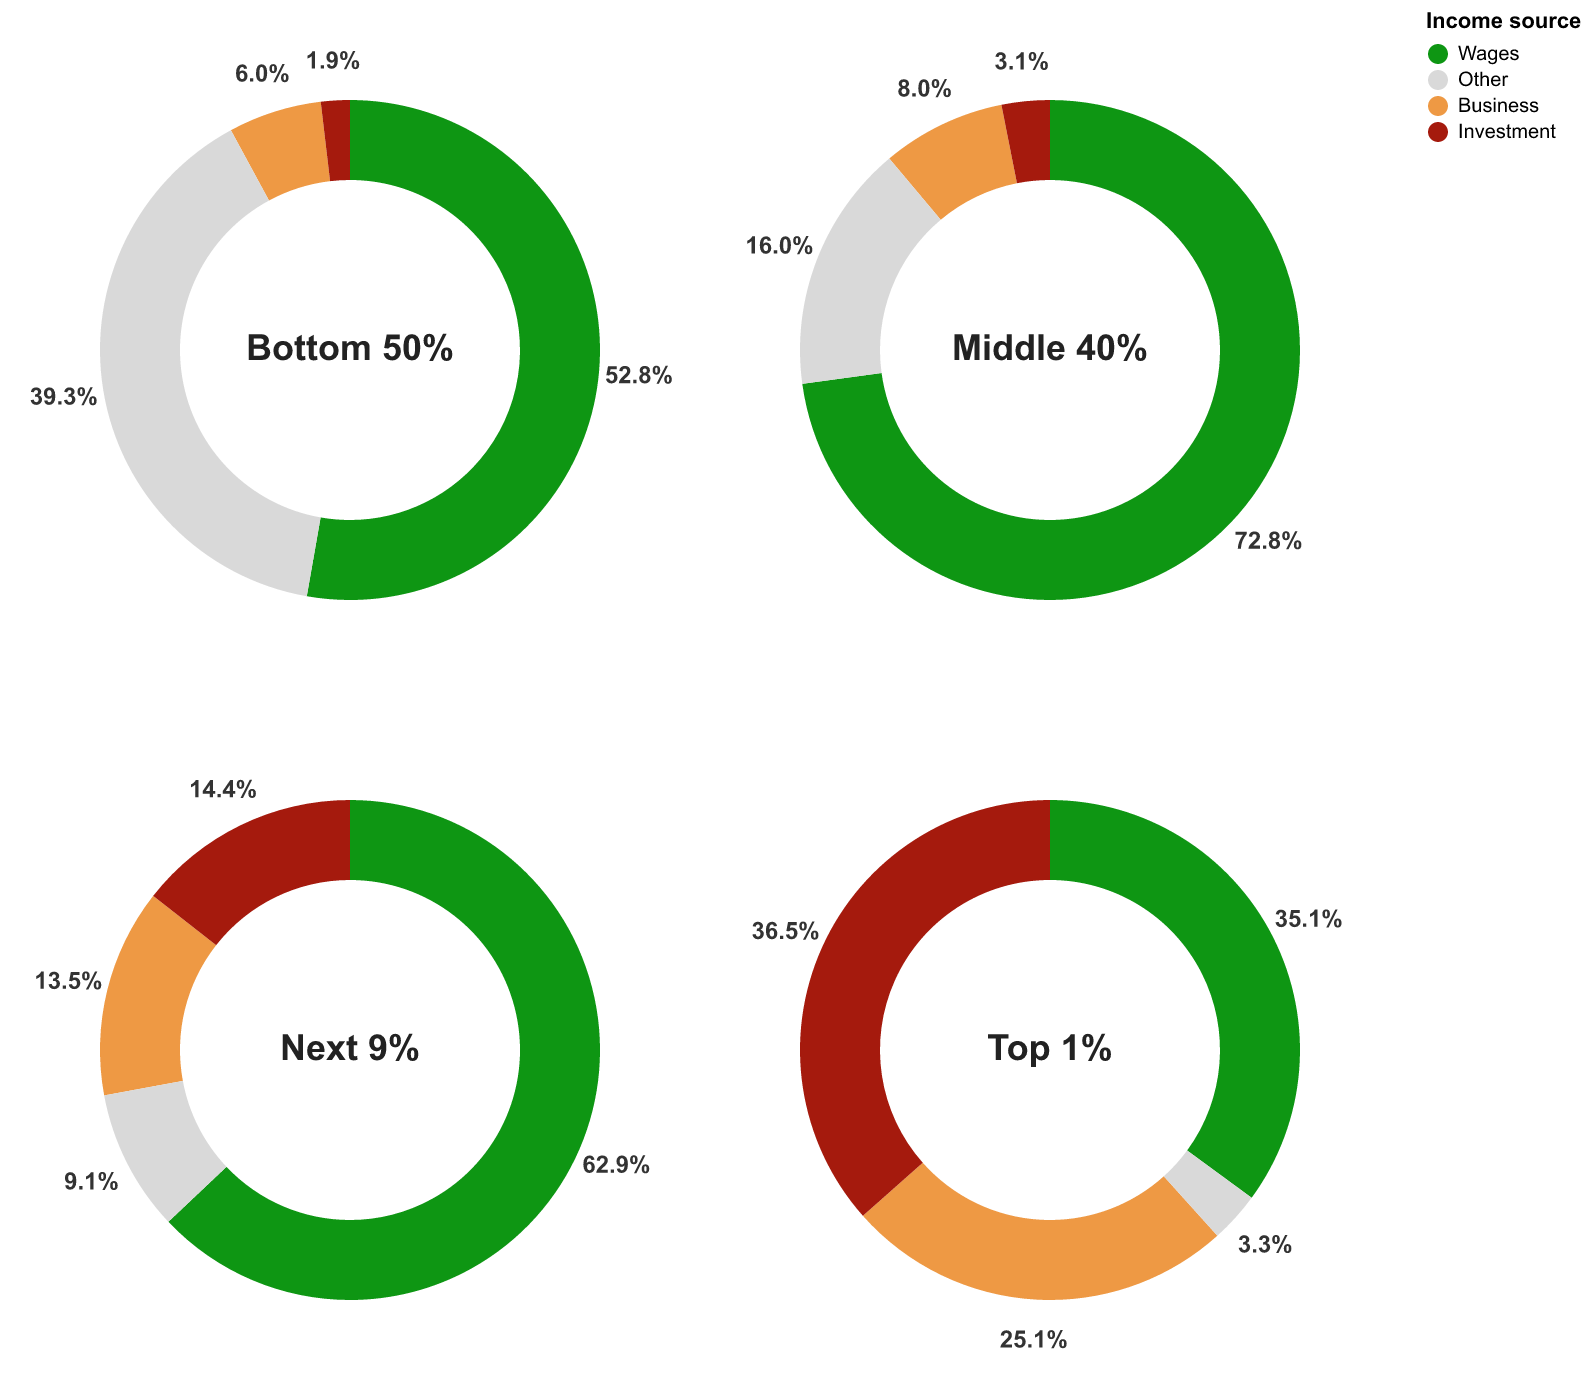

In [92]:
# 1. Income group names and order
income_order = [
    "Bottom 50%",
    "Middle 40%",
    "Next 9%",
    "Top 1%"
]

# 2. Categories in CLOCKWISE order
category_order = [
    "Wages",
    "Other",
    "Business",
    "Investment"
]

category_colors = [
    "#0E9613",  # Wages - green
    "#D9D9D9",  # Other - gray
    "#EE9944",  # Business - orange
    "#A51A0D"   # Investment - dark red
]

# 3. Prepare data
donut_data = chart_data.copy()

# Rename the income group
donut_data["Income group"] = donut_data["Income group"].replace({
    "Next 40%": "Middle 40%"
})

# Combine interest/dividends and capital gains
donut_data["Category"] = donut_data["Income source"].replace({
    "Wages": "Wages",
    "Business income": "Business",
    "Interest & dividends": "Investment",
    "Capital gains": "Investment"
})

donut_data = (
    donut_data.groupby(
        ["Income group", "Category"],
        as_index=False
    )["Share (%)"].sum()
)

# 4. Calculate Other income
remaining = (
    donut_data.groupby(
        "Income group", as_index=False
    )["Share (%)"].sum()
)

remaining["Share (%)"] = 100 - remaining["Share (%)"]
remaining["Category"] = "Other"

donut_data = pd.concat(
    [donut_data, remaining],
    ignore_index=True
)

# 5. Set clockwise stacking order
donut_data["sort_order"] = donut_data["Category"].map({
    category: i
    for i, category in enumerate(category_order)
})

# Create percentage labels
donut_data["label"] = donut_data["Share (%)"].map(
    lambda x: f"{x:.1f}%"
)

# 6. Create donut function
def make_donut(group):

    data = donut_data[
        donut_data["Income group"] == group
    ].copy()

    base = alt.Chart(data).encode(
        theta=alt.Theta(
            "Share (%):Q",
            stack=True
        ),
        order=alt.Order(
            "sort_order:Q",
            sort="ascending"
        )
    )

    # Donut
    donut = base.mark_arc(
        innerRadius=85,
        outerRadius=125
    ).encode(
        color=alt.Color(
            "Category:N",
            scale=alt.Scale(
                domain=category_order,
                range=category_colors
            ),
            legend=alt.Legend(
                title="Income source",
                values=category_order
            )
        ),
        tooltip=[
            "Income group:N",
            "Category:N",
            alt.Tooltip(
                "Share (%):Q",
                format=".1f",
                title="Share (%)"
            )
        ]
    )

    # Percentage labels outside the ring
    percentages = base.mark_text(
        radius=145,
        fontSize=12,
        fontWeight="bold",
        color="#333333"
    ).encode(
        text="label:N"
    )

    # Income group name in the center
    center = alt.Chart(
        pd.DataFrame({"group": [group]})
    ).mark_text(
        fontSize=18,
        fontWeight="bold",
        color="#222222"
    ).encode(
        text="group:N"
    )

    return (
        donut + percentages + center
    ).properties(
        width=340,
        height=340
    )

# 7. Arrange charts in 2 x 2 layout
chart_donuts = alt.vconcat(
    alt.hconcat(
        make_donut("Bottom 50%"),
        make_donut("Middle 40%"),
        spacing=10
    ),
    alt.hconcat(
        make_donut("Next 9%"),
        make_donut("Top 1%"),
        spacing=10
    ),
    spacing=10
).resolve_scale(
    color="shared"
)

from IPython.display import Image, display

chart_donuts.save("../img/03.png", scale_factor=2)
chart_donuts.save("../img/03.svg")
display(Image(filename="../img/03.png"))

## Section4 Chart1 race/ethnicity

In [74]:
# CPS ASEC 2026: annual earnings for 2025
data_path = Path("../data/pppub26.csv")

df_earnings = pd.read_csv(
    data_path,
    usecols=[
        "PEHSPNON",
        "PRDTRACE",
        "PEARNVAL",
        "A_FNLWGT",
    ],
)

# Classify race/ethnicity, combining male and female
conditions = [
    df_earnings["PEHSPNON"] == 1,
    (df_earnings["PRDTRACE"] == 1) & (df_earnings["PEHSPNON"] == 2),
    (df_earnings["PRDTRACE"] == 2) & (df_earnings["PEHSPNON"] == 2),
    (df_earnings["PRDTRACE"] == 4) & (df_earnings["PEHSPNON"] == 2),
]

choices = ["Hispanic", "White", "Black", "Asian"]

df_earnings["race_group2"] = np.select(
    conditions,
    choices,
    default="Other/Multiracial",
)

box_data2 = df_earnings[
    (df_earnings["PEARNVAL"] > 0)
    & (df_earnings["A_FNLWGT"] > 0)
    & (df_earnings["race_group2"] != "Other/Multiracial")
].copy()

In [75]:
def weighted_percentile(values, weights, percentile):
    order = np.argsort(values)
    values = np.asarray(values)[order]
    weights = np.asarray(weights)[order]

    cumulative_weights = np.cumsum(weights)
    cutoff = weights.sum() * percentile / 100

    return values[np.searchsorted(cumulative_weights, cutoff)]


box_summary2 = (
    box_data2.groupby("race_group2")
    .apply(
        lambda g: pd.Series({
            "p25": weighted_percentile(
                g["PEARNVAL"], g["A_FNLWGT"], 25
            ),
            "median": weighted_percentile(
                g["PEARNVAL"], g["A_FNLWGT"], 50
            ),
            "p75": weighted_percentile(
                g["PEARNVAL"], g["A_FNLWGT"], 75
            ),
        }),
        include_groups=False,
    )
    .reset_index()
)

box_summary2["median_label"] = box_summary2["median"].map(
    lambda x: f"${x:,.0f}"
)

display(box_summary2)

,race_group2,p25,median,p75,median_label
0,Asian,36000,72000,130000,"$72,000"
1,Black,28000,48000,75000,"$48,000"
2,Hispanic,25000,42000,68000,"$42,000"
3,White,30000,60000,100000,"$60,000"


In [ ]:
group_order2 = ["White", "Black", "Hispanic", "Asian"]
group_colors2 = ["#723C91", "#1EBA1B", "#FA8825", "#A51A0D"]

base2 = alt.Chart(box_summary2).encode(
    y=alt.Y(
        "race_group2:N",
        sort=group_order2,
        title="Race / Ethnicity",
    )
)

boxes2 = base2.mark_bar(size=22).encode(
    x=alt.X(
        "p25:Q",
        title="Annual earnings ($)",
        axis=alt.Axis(format="$,.0f"),
    ),
    x2="p75:Q",
    color=alt.Color(
        "race_group2:N",
        scale=alt.Scale(
            domain=group_order2,
            range=group_colors2,
        ),
        legend=None,
    ),
)

medians2 = base2.mark_tick(
    color="white",
    thickness=3,
    size=22,
).encode(
    x="median:Q",
)

median_labels2 = base2.mark_text(
    dy=-18,
    fontSize=13,
    fontWeight="bold",
    color="black",
).encode(
    x="median:Q",
    text="median_label:N",
)

chart03 = (
    boxes2 + medians2 + median_labels2
).properties(
    width=650,
    height=250,
    title="Median Annual Earnings by Race/Ethnicity (2025)",
)

# Export
output_dir = Path("../img")
output_dir.mkdir(parents=True, exist_ok=True)

chart03

alt.LayerChart(...)

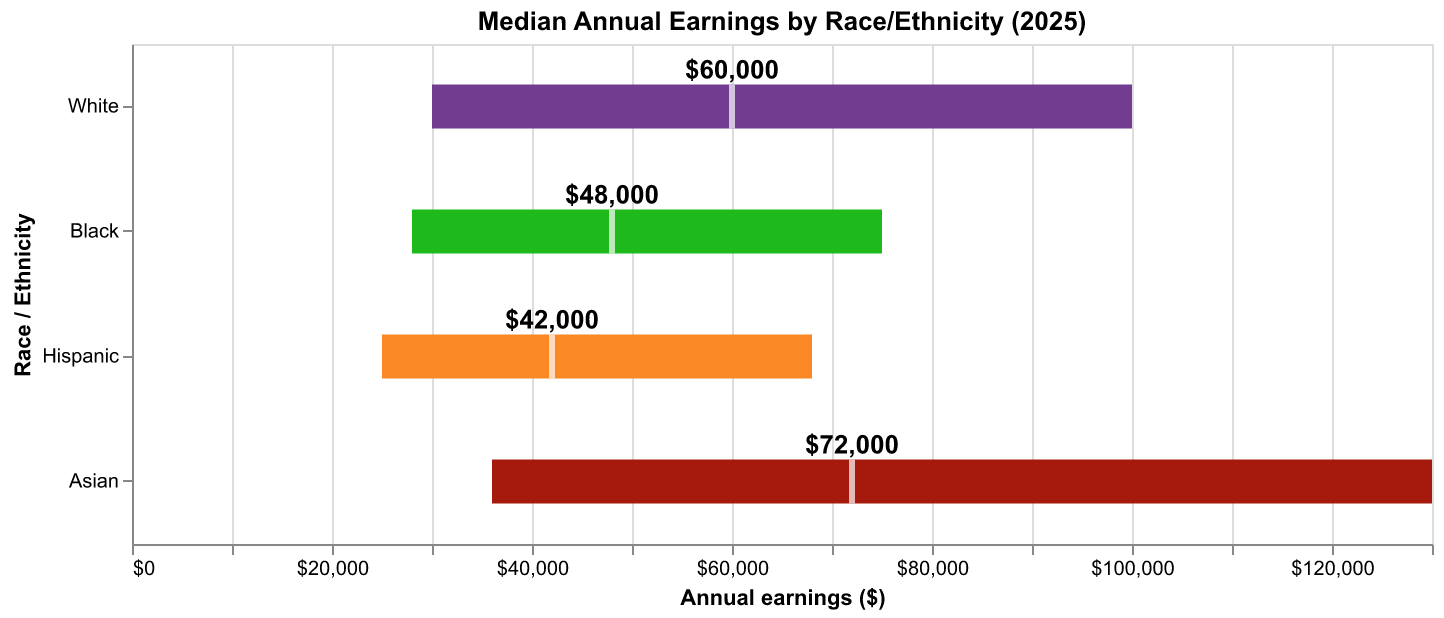

In [93]:
chart03.save("../img/04a.png", scale_factor=2)
chart03.save("../img/04a.svg")

display(Image(filename="../img/04a.png"))

In [79]:
population = pd.DataFrame({
    "Group": ["White", "Hispanic", "Black", "Asian", "Other"],
    "Population": [
        191697647, 62080044, 39940338, 19618719, 18112533
    ]
})

population["Percent"] = (
    population["Population"] / population["Population"].sum() * 100
)

population["Label"] = population["Percent"].map(
    lambda x: f"{x:.1f}%"
)

group_order = ["White", "Hispanic", "Black", "Asian", "Other"]

population["sort_order"] = population["Group"].map({
    "White": 0,
    "Hispanic": 1,
    "Black": 2,
    "Asian": 3,
    "Other": 4
})

base = alt.Chart(population).encode(
    theta=alt.Theta("Population:Q", stack=True),
    order=alt.Order("sort_order:Q", sort="ascending"),
    color=alt.Color(
        "Group:N",
        scale=alt.Scale(
            domain=group_order,
            range=["#723C91", "#FA8825", "#1EBA1B",
                   "#A51A0D", "#999999"]
        ),
        legend=alt.Legend(title="Race / Ethnicity")
    )
)

pie = base.mark_arc(outerRadius=120)

labels = base.mark_text(
    radius=145,
    fontSize=13,
    fontWeight="bold"
).encode(text="Label:N")

chart03b = (pie + labels).properties(
    width=340,
    height=340,
    title="U.S. Population by Race/Ethnicity (2020)"
)

chart03b

alt.LayerChart(...)

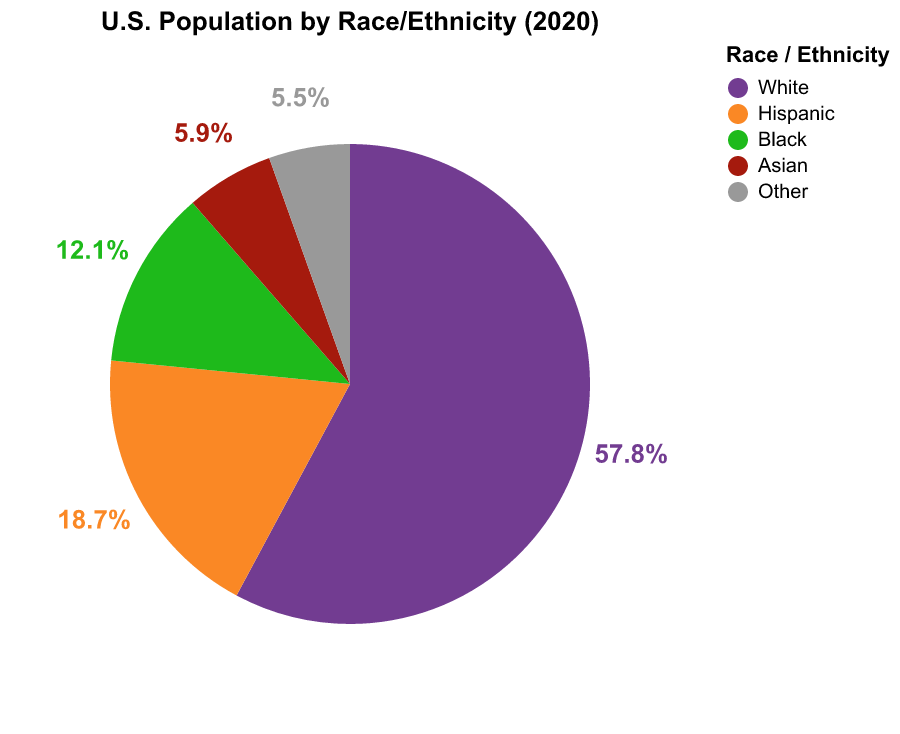

In [94]:
chart03b.save("../img/04b.png", scale_factor=2)
chart03b.save("../img/04b.svg")

display(Image(filename="../img/04b.png"))

## Section4 Chart2 Gini, immigrants

In [82]:
df_081 = pd.read_csv(
    "../data/immigrants_2024.csv",
    skiprows=2
)

df_081 = df_081.rename(columns={
    "Year": "year",
    "Immigrants as a Percentage of the U.S. Population": "immigrant_share"
})

df_081["year"] = pd.to_numeric(df_081["year"], errors="coerce")

df_081["immigrant_share"] = pd.to_numeric(
    df_081["immigrant_share"].str.replace("%", "", regex=False),
    errors="coerce"
)

df_081 = df_081.dropna(subset=["year", "immigrant_share"])

df_081.head()

,year,Number of Immigrants,immigrant_share
0,1850.0,"2,244,600",9.7
1,1860.0,"4,138,700",13.2
2,1870.0,"5,567,200",14.4
3,1880.0,"6,679,900",13.3
4,1890.0,"9,249,500",14.8


In [83]:
df_082 = pd.read_csv("../data/GINIALLRH.csv")
df_082["year"] = pd.to_datetime(df_082["observation_date"]).dt.year
df_082 = df_082.rename(columns={"GINIALLRH": "gini"})

chart08_data = pd.merge(
    df_081[["year", "immigrant_share"]],
    df_082[["year", "gini"]],
    on="year",
    how="inner"
)

chart08_data = (
    chart08_data[chart08_data["year"] >= 1990]
    .sort_values("year")
    .copy()
)

print(chart08_data[["year", "immigrant_share", "gini"]].to_string(index=False))
print("Observations:", len(chart08_data))

  year  immigrant_share  gini
1990.0              7.9 0.428
2000.0             11.1 0.462
2010.0             12.9 0.470
2011.0             13.0 0.477
2012.0             13.0 0.477
2013.0             13.1 0.482
2014.0             13.3 0.480
2015.0             13.5 0.479
2016.0             13.5 0.481
2017.0             13.7 0.489
2018.0             13.7 0.486
2019.0             13.7 0.484
2021.0             13.6 0.494
2022.0             13.9 0.488
2023.0             14.3 0.485
2024.0             14.8 0.489
Observations: 16


In [84]:
selected_years = [1990, 2000, 2010, 2015, 2019, 2024]

chart08_data = chart08_data[
    chart08_data["year"].isin(selected_years)
].copy()

In [85]:
base08 = alt.Chart(chart08_data).encode(
    x=alt.X(
        "immigrant_share:Q",
        title="Foreign-born share of U.S. population (%)",
        scale=alt.Scale(zero=False)
    ),
    y=alt.Y(
        "gini:Q",
        title="Household income Gini coefficient",
        scale=alt.Scale(zero=False)
    )
)

line08 = base08.mark_line(
    color="#9CA3AF",
    strokeWidth=2,
    opacity=0.75
).encode(
    order=alt.Order("year:Q", sort="ascending")
)

dots08 = base08.mark_circle(
    size=110,
    stroke="white",
    strokeWidth=1
).encode(
    color=alt.Color(
        "year:Q",
        scale=alt.Scale(scheme="viridis"),
        title="Year"
    ),
    tooltip=[
        alt.Tooltip("year:Q", title="Year", format=".0f"),
        alt.Tooltip("immigrant_share:Q", title="Foreign-born share (%)", format=".1f"),
        alt.Tooltip("gini:Q", title="Gini coefficient", format=".3f")
    ]
)


labels08 = (
    base08
    .mark_text(
        align="left",
        dx=9,
        dy=-9,
        fontSize=10,
        color="#333333"
    )
    .encode(
        text=alt.Text("year:Q", format=".0f")
    )
)


chart08 = (
    (line08 + dots08 + labels08)
    .properties(
        width=700,
        height=450,
        title="Immigration and Household Income Inequality in the U.S."
    )
)

chart08

alt.LayerChart(...)

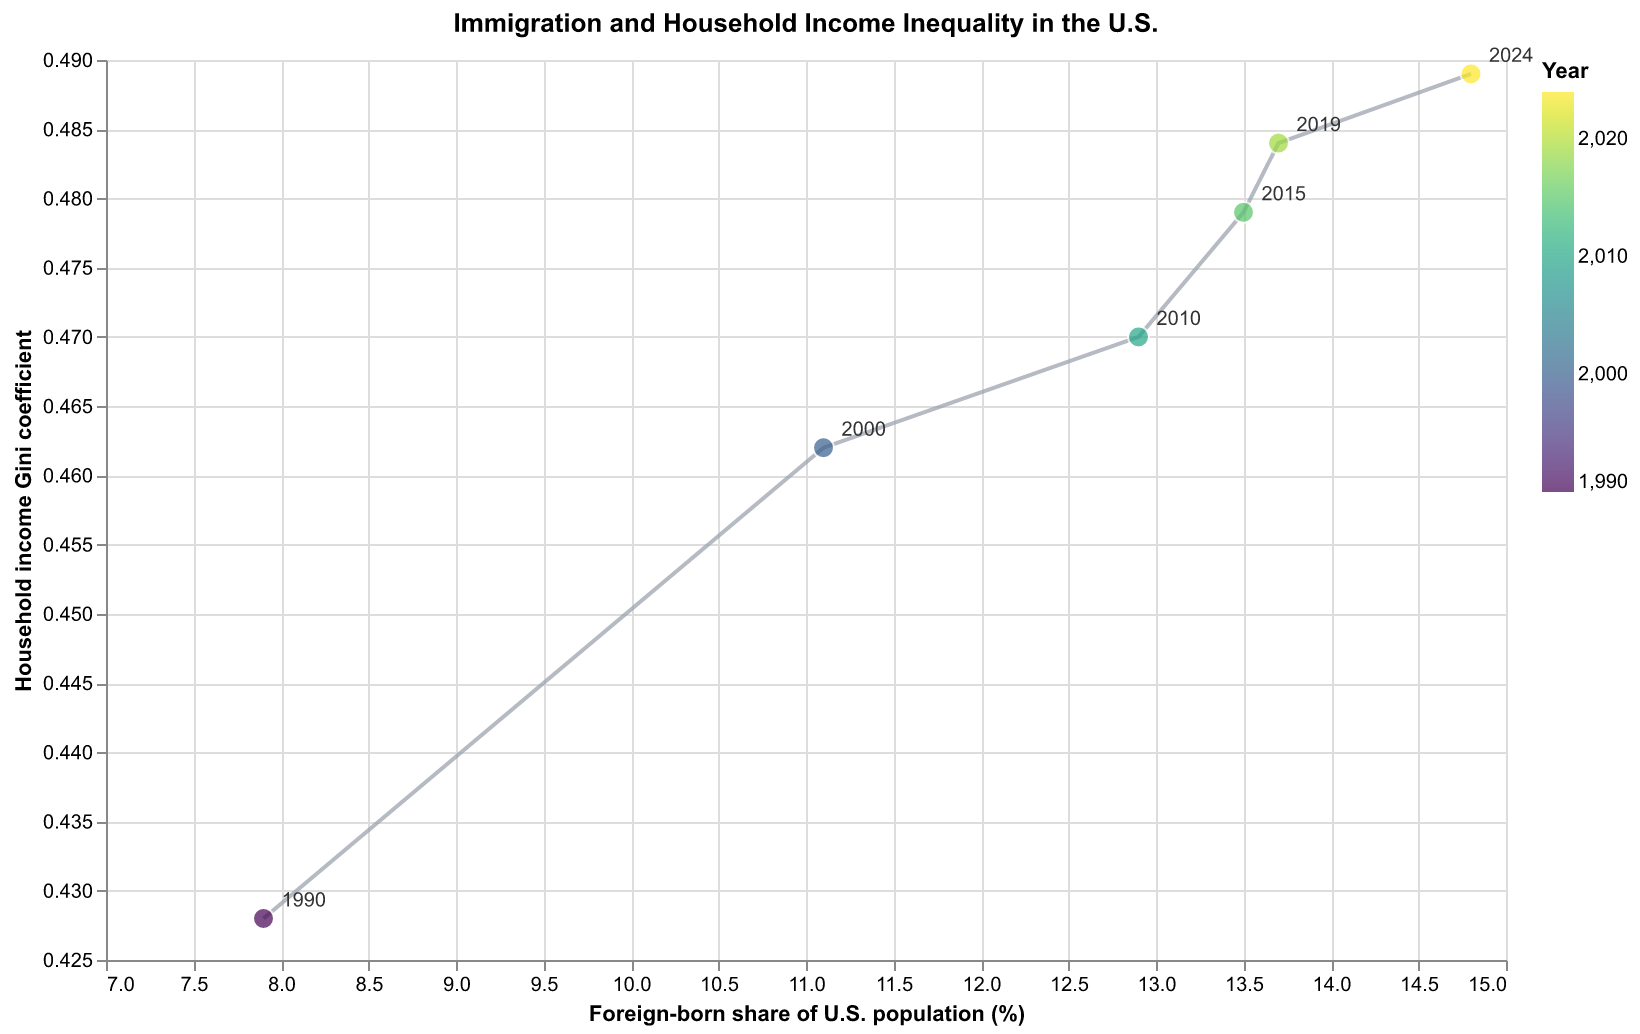

In [95]:
chart08.save("../img/04c.png", scale_factor=2)
chart08.save("../img/04c.svg")
display(Image(filename="../img/04c.png"))